# 자연어 처리 5일차 (2) — self-attention 을 손으로 : Q · K · V → Scaled Dot-Product Attention

수업 필기 `nlp_실습8` 을 **실행 가능하도록 정리 · 개선한 노트**입니다.
(교재 `자연어처리` 교재v1 **p.90~96** — self-attention · 과정 1 입력 임베딩 + 위치 정보 · 과정 2 Q · K · V · 과정 3 Scaled Dot-Product Attention · 어텐션 출력)

$$\mathrm{Attention}(Q, K, V) = \mathrm{softmax}\!\left(\frac{QK^{\top}}{\sqrt{d_k}}\right)V$$

```
'I love you' → 토큰 번호 → 임베딩 (3, 512) + 위치 정보 → × W (512, 1536) → Q · K · V 각 (3, 512)
            → Q Kᵀ (3, 3) → ÷ √512 → softmax (행마다 합 1) → × V → 문맥 반영 벡터 (3, 512)
```

- 앞 노트 : [`rnn_limits_seq2seq.ipynb`](./rnn_limits_seq2seq.ipynb) (왜 어텐션이 필요한가)
- 원본에서 고친 부분은 **📝 고친 부분** 으로 적었습니다.

## 0. 설치 · 실행 방법

| 패키지 | 이 노트에서 쓰는 것 | 설치 |
|---|---|---|
| `torch` | 행렬 곱 · softmax · `F.scaled_dot_product_attention` 로 확인 | Colab 기본 포함 · 로컬은 `pip install torch` |
| `transformers` | BERT 의 WordPiece 토크나이저로 `I love you` → 토큰 번호 (§1, 사전 크기 30,522) | Colab 기본 포함 · 로컬은 `pip install transformers` — 첫 실행 때 사전 파일(약 0.5MB)을 받는다 · **인터넷 필요** |
| `matplotlib` | 히트맵 | Colab 기본 포함 |

**실행 순서** : 맨 위부터 **[런타임] → [모두 실행]**. GPU 없이 몇 초. 토크나이저를 못 받으면 §1 은 BERT 사전의 번호 `[1045, 2293, 2017]` 를 그대로 쓰면 된다.

In [1]:
# ① 설치 (로컬에서 처음 한 번 — Colab 은 기본 포함)
# !pip install -q torch transformers matplotlib

In [2]:
# 그래프 한글 폰트 설정 (운영체제별)
import platform
import matplotlib.pyplot as plt

if platform.system() == 'Windows':
    plt.rcParams['font.family'] = 'Malgun Gothic'
elif platform.system() == 'Darwin':
    plt.rcParams['font.family'] = 'AppleGothic'
# Colab(리눅스) : !apt-get install -y fonts-nanum 후 런타임 재시작 → plt.rcParams['font.family'] = 'NanumGothic'
plt.rcParams['axes.unicode_minus'] = False

In [3]:
import math
import torch
import torch.nn as nn
import torch.nn.functional as F
import warnings
warnings.filterwarnings('ignore')
torch.manual_seed(0)                         # 원본은 시드가 없어 실행할 때마다 숫자가 바뀐다
torch.set_grad_enabled(False)                # 학습하지 않고 계산만 — 출력에 grad_fn 이 붙지 않게
torch.set_printoptions(precision=4, sci_mode=False)
d_model = 512

## 1. 과정 1 — 토큰화 → 정수 번호 → 임베딩 + 위치 정보 (교재 p.91)

In [4]:
from transformers import AutoTokenizer
tok = AutoTokenizer.from_pretrained('bert-base-uncased')       # WordPiece · 사전 30,522개
words = tok.tokenize('I love you')
ids = tok.convert_tokens_to_ids(words)
print('토큰 :', words, '| 번호 :', ids, '| 사전 크기 :', tok.vocab_size)
print('WordPiece 예 :', tok.tokenize('I love transformers and embeddings'))

토큰 : ['i', 'love', 'you'] | 번호 : [1045, 2293, 2017] | 사전 크기 : 30522
WordPiece 예 : ['i', 'love', 'transformers', 'and', 'em', '##bed', '##ding', '##s']


In [5]:
vocab_size, max_len = tok.vocab_size, 512
word_emb = nn.Embedding(vocab_size, d_model)             # 가중치 (30522, 512)
pos_emb = nn.Embedding(max_len, d_model)                 # 학습하는 위치 임베딩 (512, 512) — BERT · GPT 방식

x_ids = torch.tensor(ids)
positions = torch.arange(len(ids))                       # 0, 1, 2
X_word = word_emb(x_ids)                                 # (3, 512) — 사전에서 해당 행을 꺼낸다(lookup)
X = X_word + pos_emb(positions)                          # 단어 + 위치 → (3, 512)
print('단어 임베딩', tuple(X_word.shape), '+ 위치', tuple(pos_emb(positions).shape), '=', tuple(X.shape))
print('lookup 확인 :', torch.equal(X_word[1], word_emb.weight[ids[1]]))

단어 임베딩 (3, 512) + 위치 (3, 512) = (3, 512)
lookup 확인 : True


d=4 일 때 위치 0 · 1 · 2 의 값 (짝수칸 sin · 홀수칸 cos) :
 tensor([[ 0.0000,  1.0000,  0.0000,  1.0000],
        [ 0.8415,  0.5403,  0.0100,  0.9999],
        [ 0.9093, -0.4161,  0.0200,  0.9998]])

교재 그림 값 0.84 · 0.54 = sin(1) · cos(1) : 0.84 0.54 | 0.91 · −0.42 = sin(2) · cos(2) : 0.91 -0.42


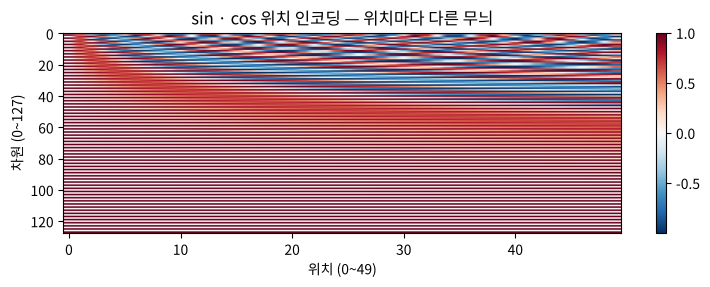

In [6]:
# 원 논문(Transformer) 의 위치 정보 : 학습하지 않는 sin · cos 고정값
def sinusoidal(n_pos, d):
    pe = torch.zeros(n_pos, d)
    pos = torch.arange(n_pos).unsqueeze(1)
    div = torch.exp(torch.arange(0, d, 2) * (-math.log(10000.0) / d))
    pe[:, 0::2] = torch.sin(pos * div)
    pe[:, 1::2] = torch.cos(pos * div)
    return pe

pe = sinusoidal(3, 4)
print('d=4 일 때 위치 0 · 1 · 2 의 값 (짝수칸 sin · 홀수칸 cos) :\n', pe)
print('\n교재 그림 값 0.84 · 0.54 = sin(1) · cos(1) :', round(math.sin(1), 2), round(math.cos(1), 2),
      '| 0.91 · −0.42 = sin(2) · cos(2) :', round(math.sin(2), 2), round(math.cos(2), 2))

import matplotlib.pyplot as plt
plt.figure(figsize=(9, 2.6))
plt.imshow(sinusoidal(50, 128).T, aspect='auto', cmap='RdBu_r'); plt.colorbar()
plt.xlabel('위치 (0~49)'); plt.ylabel('차원 (0~127)'); plt.title('sin · cos 위치 인코딩 — 위치마다 다른 무늬'); plt.show()

> **📝 고친 부분 (교재 p.91)**
> - 그림 왼쪽은 `position_embedding layer` **가중치 행렬 (max_length, 512)** (= 학습하는 위치 임베딩, BERT · GPT 방식), 오른쪽 `POSITIONAL ENCODING` 의 값 `0.84 · 0.54 · 0.91 · −0.42` 는 **sin · cos 고정값**(원 Transformer 논문 방식)이다 — 위 계산과 같다. 두 방식은 다르며 둘 다 쓰인다
> - 원 논문의 토큰화는 영어-독일어 **BPE**(약 37,000개) · 영어-프랑스어 **word-piece**(32,000개). WordPiece 를 쓰는 대표 모델은 BERT(30,522개)
> - 원본 필기 docstring '크기가 30000 인 단어 사전 … [250, 12000, 700]' 은 예시 숫자 — 실제 BERT 사전에서 `I love you` 는 `[1045, 2293, 2017]`

## 2. 과정 2 — 가중치 하나로 Q · K · V 한꺼번에 (교재 p.92)

In [7]:
# 가중치 W_q · W_k · W_v (각 512×512) 를 한 행렬 (512, 1536) 으로 — 원본과 같은 방식
weights_matrix = torch.randn(d_model, d_model * 3) / math.sqrt(d_model)    # √512 로 나눠 값 크기를 줄임
W_q, W_k, W_v = weights_matrix.split(d_model, dim=1)                       # [:, 0:512] · [:, 512:1024] · [:, 1024:]
print('W 모양', tuple(weights_matrix.shape), '→', [tuple(w.shape) for w in (W_q, W_k, W_v)])

qkv = X @ weights_matrix                    # (3, 512) @ (512, 1536) = (3, 1536)
query, key, value = qkv.split(d_model, dim=1)
print('qkv', tuple(qkv.shape), '→ query · key · value 각', tuple(query.shape))
print('따로 곱한 것과 같은가 ?', torch.allclose(query, X @ W_q, atol=1e-5), torch.allclose(value, X @ W_v, atol=1e-5))

W 모양 (512, 1536) → [(512, 512), (512, 512), (512, 512)]
qkv (3, 1536) → query · key · value 각 (3, 512)
따로 곱한 것과 같은가 ? True True


`torch.randn` 은 평균 0 · 표준편차 1 이라 512개를 곱해 더하면 값이 √512 ≈ 22.6 배로 커진다 → 원본처럼 **√d_model 로 나눠** 시작 값을 작게 두는 것이 맞다(학습할 때는 `nn.Linear` 가 비슷한 초기화를 자동으로 한다).

> **📝 고친 부분 (원본 cell 3 · 4)** 오타 `각중치` → 가중치. 슬라이싱 `[:, 0:512]` 는 `split(512, dim=1)` 한 줄로 같다.

## 3. 과정 3 — Scaled Dot-Product Attention (교재 p.94)

### 3-1. attention score = Q Kᵀ

In [8]:
attention_score = query @ key.mT            # (3, 512) @ (512, 3) = (3, 3) — key 를 전치(transpose)
print('attention score (행 = query 단어, 열 = key 단어):\n', attention_score)
print('\n[0,1] 칸 = q(I) · k(love) 내적 :', round((query[0] * key[1]).sum().item(), 4))

attention score (행 = query 단어, 열 = key 단어):
 tensor([[-42.0404, -54.9646,  19.3928],
        [-17.6542, -44.6544,  18.0963],
        [ 13.3018, -28.7711,  51.3259]])

[0,1] 칸 = q(I) · k(love) 내적 : -54.9646


### 3-2. scaling — 왜 √d_k 로 나누나

In [9]:
# 원소가 평균 0 · 분산 1 인 두 벡터의 내적 → 분산이 차원 d 만큼 커진다
for d in [4, 64, 512]:
    a, b = torch.randn(10000, d), torch.randn(10000, d)
    dots = (a * b).sum(1)
    print(f'd = {d:3d} : 내적의 표준편차 {dots.std():6.2f} (√d = {math.sqrt(d):5.2f}) → ÷√d 후 {(dots / math.sqrt(d)).std():.2f}')

s = torch.tensor([2.0, 1.0, 0.0])
for k in [1, 8, 22.6]:
    print(f'점수 × {k:4} → softmax {F.softmax(s * k, dim=-1).numpy().round(3)}')

d =   4 : 내적의 표준편차   2.02 (√d =  2.00) → ÷√d 후 1.01
d =  64 : 내적의 표준편차   7.94 (√d =  8.00) → ÷√d 후 0.99


d = 512 : 내적의 표준편차  22.67 (√d = 22.63) → ÷√d 후 1.00
점수 ×    1 → softmax [0.665 0.245 0.09 ]
점수 ×    8 → softmax [1. 0. 0.]
점수 × 22.6 → softmax [1. 0. 0.]


점수가 크면 softmax 가 한 칸에 **거의 1, 나머지 0** 으로 쏠린다(포화) → 기울기가 거의 0 이 되어 학습이 막힌다. 그래서 $\sqrt{d_k}$ 로 나눠 분산을 1 근처로 되돌린다.

In [10]:
d_k = key.shape[-1]                         # key 벡터 차원 (여기서는 512, head 하나)
scaled_attention_score = attention_score / math.sqrt(d_k)
print('scaled score:\n', scaled_attention_score)

scaled score:
 tensor([[-1.8579, -2.4291,  0.8570],
        [-0.7802, -1.9735,  0.7998],
        [ 0.5879, -1.2715,  2.2683]])


### 3-3. attention weight = softmax (행마다)

In [11]:
attention_weight = F.softmax(scaled_attention_score, dim=-1)     # 마지막 축 = key 방향 → 각 행의 합 1
print('attention weight:\n', attention_weight)
print('행 합 :', attention_weight.sum(dim=-1))
print('dim=0 으로 하면 행 합이 1 이 아니다 (틀린 방향) :', F.softmax(scaled_attention_score, dim=0).sum(dim=-1))

attention weight:
 tensor([[0.0600, 0.0339, 0.9061],
        [0.1624, 0.0492, 0.7884],
        [0.1533, 0.0239, 0.8228]])
행 합 : tensor([1., 1., 1.])
dim=0 으로 하면 행 합이 1 이 아니다 (틀린 방향) : tensor([0.4036, 0.6199, 1.9765])


> **📝 고친 부분 (원본 cell 13)** `F.softmax(scaled_attention_score)` → `UserWarning: Implicit dimension choice` 경고. 2차원이면 자동으로 `dim=1` 이 골라져 결과는 맞았지만, 배치가 붙어 3차원이 되면 **엉뚱한 축**이 될 수 있다 → 항상 **`dim=-1`**(key 방향)로 적는다.

### 3-4. attention output = weight × V (교재 p.95~96)

In [12]:
output = attention_weight @ value           # (3, 3) @ (3, 512) = (3, 512)
print('output 모양 :', tuple(output.shape))

# 'I' 의 새 벡터 = w[0,0]·v(I) + w[0,1]·v(love) + w[0,2]·v(you)
manual = attention_weight[0, 0] * value[0] + attention_weight[0, 1] * value[1] + attention_weight[0, 2] * value[2]
print('I 행 손계산 == output[0] ?', torch.allclose(manual, output[0], atol=1e-5))
print(f'이번 실행의 I : I {attention_weight[0, 0]:.0%} + love {attention_weight[0, 1]:.0%} + you {attention_weight[0, 2]:.0%}')

# PyTorch 내장 함수와 비교
ref = F.scaled_dot_product_attention(query.unsqueeze(0), key.unsqueeze(0), value.unsqueeze(0))[0]
print('F.scaled_dot_product_attention 과 같은가 ?', torch.allclose(ref, output, atol=1e-5))

output 모양 : (3, 512)
I 행 손계산 == output[0] ? True
이번 실행의 I : I 6% + love 3% + you 91%
F.scaled_dot_product_attention 과 같은가 ? True


In [13]:
# 교재 p.96 예시 숫자로 — value 의 앞 칸만 (I : 0.1 · love : 0.2 · you : 0.5)
w_book = torch.tensor([[0.9, 0.03, 0.07], [0.05, 0.85, 0.1], [0.06, 0.04, 0.9]])
v_book = torch.tensor([[0.1], [0.2], [0.5]])
print('교재 weight 행 합 :', w_book.sum(1))
print('새 I 의 첫 칸 = 0.9×0.1 + 0.03×0.2 + 0.07×0.5 =', round((w_book @ v_book)[0, 0].item(), 3))

교재 weight 행 합 : tensor([1.0000, 1.0000, 1.0000])
새 I 의 첫 칸 = 0.9×0.1 + 0.03×0.2 + 0.07×0.5 = 0.131


> **📝 고친 부분 (원본 cell 15 · 교재 p.96)**
> - 주석 '반영 비율 × (**각 단어의 임베딩 행렬**)' · 교재 'I 정보 × 90% + …' 의 '정보' → 곱하는 대상은 원래 임베딩이 아니라 **value 벡터** $v = xW_v$ 다
> - 교재 p.94 · 95 표처럼 **자기 자신에 0.9** 가 몰리는 것은 설명용 예시다. 학습 전 무작위 가중치에서는 위 결과처럼 아무 단어에나 몰릴 수 있고, 어떤 단어를 볼지는 **학습으로** 정해진다
> - 오타 `곱셉` · `이용행서` · `백터` · `로분터` → 곱셈 · 이용해서 · 벡터 · 로부터. 비어 있는 마지막 셀 `##` 삭제

## 4. 히트맵으로 보기

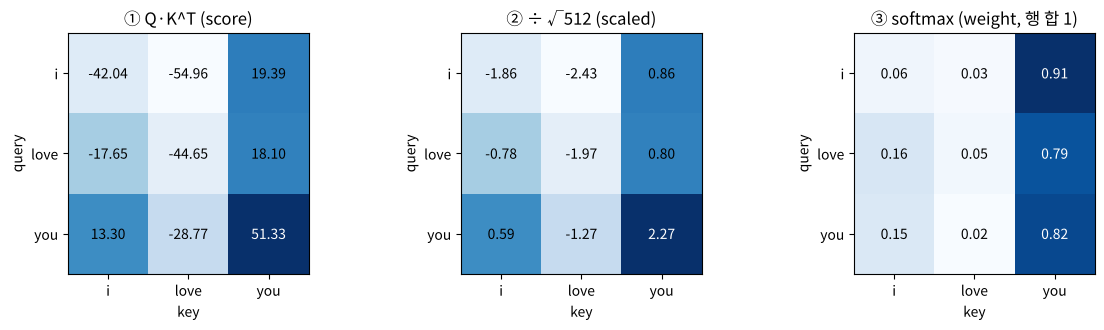

In [14]:
labels = words
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
for ax, M, title in zip(axes, [attention_score, scaled_attention_score, attention_weight],
                        ['① Q·K^T (score)', '② ÷ √512 (scaled)', '③ softmax (weight, 행 합 1)']):
    im = ax.imshow(M.detach(), cmap='Blues')
    ax.set_xticks(range(3), labels); ax.set_yticks(range(3), labels)
    ax.set_xlabel('key'); ax.set_ylabel('query'); ax.set_title(title)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f'{M[i, j]:.2f}', ha='center', va='center', fontsize=10,
                    color='white' if M[i, j] > M.max() * 0.6 else 'black')
plt.tight_layout(); plt.show()

## 5. 위치 정보가 없으면 — 순서를 모른다

In [15]:
def self_attention(X):
    q, k, v = (X @ weights_matrix).split(d_model, dim=1)
    return F.softmax(q @ k.mT / math.sqrt(d_model), dim=-1) @ v

perm = torch.tensor([2, 1, 0])                              # 'you love I'
out_a = self_attention(X_word)                              # 위치 정보 없이
out_b = self_attention(X_word[perm])
print('위치 없음 : 순서를 바꾸면 결과도 줄만 바뀐다(내용 같음) →', torch.allclose(out_a[perm], out_b, atol=1e-5))

out_c = self_attention(X_word + pos_emb(positions))
out_d = self_attention(X_word[perm] + pos_emb(positions))
print('위치 있음 : 순서를 바꾸면 결과가 달라진다              →', not torch.allclose(out_c[perm], out_d, atol=1e-4))

위치 없음 : 순서를 바꾸면 결과도 줄만 바뀐다(내용 같음) → True
위치 있음 : 순서를 바꾸면 결과가 달라진다              → True


self-attention 의 계산에는 순서가 없다 — `I love you` 와 `you love I` 에서 `love` 의 결과가 똑같다. 그래서 과정 1 에서 **위치 정보를 더한다**.

## 6. 같은 단어 · 다른 문맥 → 다른 벡터 (contextual embedding, 교재 p.90)

In [16]:
def encode(sentence):
    t = tok.tokenize(sentence)
    i = torch.tensor(tok.convert_tokens_to_ids(t))
    Xs = word_emb(i) + pos_emb(torch.arange(len(i)))
    return t, self_attention(Xs)

t1, o1 = encode('I love you')
t2, o2 = encode('you love me')
v1, v2 = o1[t1.index('love')], o2[t2.index('love')]
i1, i2 = t1.index('love'), t2.index('love')                # 두 문장 모두 위치 1
x1 = word_emb(torch.tensor(tok.convert_tokens_to_ids('love'))) + pos_emb(torch.tensor(i1))
x2 = word_emb(torch.tensor(tok.convert_tokens_to_ids('love'))) + pos_emb(torch.tensor(i2))
print('두 문장의 love 입력 벡터(단어 + 위치)는 같다 :', torch.equal(x1, x2))
print('self-attention 뒤 두 love 의 코사인 유사도 :', round(F.cosine_similarity(v1, v2, dim=0).item(), 3), '(1 이 아니다 → 문맥 반영)')

두 문장의 love 입력 벡터(단어 + 위치)는 같다 : True
self-attention 뒤 두 love 의 코사인 유사도 : 0.609 (1 이 아니다 → 문맥 반영)


Day 041 의 BoW · Day 042 의 Embedding 층은 단어마다 벡터가 **하나**였다. self-attention 을 지나면 같은 `love` 라도 주변 단어(와 위치)에 따라 **다른 벡터**가 된다 — 이것이 contextual embedding.

## 정리

| 단계 | 코드 | 모양 |
|---|---|---|
| 임베딩 + 위치 | `word_emb(ids) + pos_emb(range)` | (3, 512) |
| Q · K · V | `(X @ W).split(512, dim=1)` | 각 (3, 512) |
| score | `q @ k.mT` | (3, 3) |
| scaling | `/ math.sqrt(d_k)` | (3, 3) |
| weight | `F.softmax(…, dim=-1)` | (3, 3), 행 합 1 |
| output | `weight @ v` | (3, 512) |
| 한 줄로 | `F.scaled_dot_product_attention(q, k, v)` | 같은 값 |